In [6]:
# ============================================================
# STAGE 6A — DASHBOARD DATA PREPARATION
# ============================================================

import pandas as pd
import numpy as np
import os

print("=" * 70)
print("STAGE 6A — DASHBOARD DATA PREPARATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. LOAD STAGE 4 PROFITABILITY DATA
# ------------------------------------------------------------

profitability = pd.read_csv(
    "../data/processed/stage4_profitability.csv"
)

print("\n✓ Stage 4 profitability data loaded")
print("Shape:", profitability.shape)


# ------------------------------------------------------------
# 2. VERIFY EXPECTED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "product_name",
    "units_sold",
    "revenue",
    "unit_cost",
    "cogs",
    "gross_profit",
    "gross_margin_pct",
    "waste_quantity",
    "waste_cost",
    "adjusted_profit",
    "adjusted_margin_pct"
]

missing_columns = [
    col for col in required_columns
    if col not in profitability.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("✓ All Stage 4 columns confirmed")


# ------------------------------------------------------------
# 3. CREATE DASHBOARD DATASET
# ------------------------------------------------------------

dashboard_products = profitability.copy()


# ------------------------------------------------------------
# 4. CALCULATE WASTE RATE
# ------------------------------------------------------------
#
# Waste rate =
# Waste quantity / (units sold + waste quantity)
#
# This measures the proportion of total product handled
# that ended up as waste.
# ------------------------------------------------------------

total_product_quantity = (
    dashboard_products["units_sold"]
    + dashboard_products["waste_quantity"]
)

dashboard_products["waste_pct"] = np.where(
    total_product_quantity > 0,
    dashboard_products["waste_quantity"]
    / total_product_quantity * 100,
    0
)


# ------------------------------------------------------------
# 5. CHECK FOR INVALID NUMERIC VALUES
# ------------------------------------------------------------

numeric_columns = [
    "units_sold",
    "revenue",
    "unit_cost",
    "cogs",
    "gross_profit",
    "gross_margin_pct",
    "waste_quantity",
    "waste_cost",
    "adjusted_profit",
    "adjusted_margin_pct",
    "waste_pct"
]

print("\nChecking numerical data quality...")

for col in numeric_columns:

    invalid_count = (
        ~np.isfinite(
            dashboard_products[col]
        )
    ).sum()

    if invalid_count > 0:
        print(
            f"⚠ {col}: "
            f"{invalid_count} invalid values"
        )

print("✓ Numerical validation complete")


# ------------------------------------------------------------
# 6. CREATE PRODUCT RANKINGS
# ------------------------------------------------------------

dashboard_products["profit_rank"] = (
    dashboard_products["adjusted_profit"]
    .rank(
        method="min",
        ascending=False
    )
    .astype("Int64")
)

dashboard_products["waste_rank"] = (
    dashboard_products["waste_cost"]
    .rank(
        method="min",
        ascending=False
    )
    .astype("Int64")
)

dashboard_products["margin_rank"] = (
    dashboard_products["adjusted_margin_pct"]
    .rank(
        method="min",
        ascending=False
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 7. CLASSIFY PRODUCTS
# ------------------------------------------------------------

def classify_product(row):

    margin = row["adjusted_margin_pct"]
    waste = row["waste_pct"]

    if margin < 5 and waste >= 20:
        return "Critical"

    elif margin < 10:
        return "Low Margin"

    elif waste >= 20:
        return "High Waste"

    elif margin >= 25:
        return "Strong"

    else:
        return "Moderate"


dashboard_products["business_status"] = (
    dashboard_products.apply(
        classify_product,
        axis=1
    )
)


# ------------------------------------------------------------
# 8. EXECUTIVE KPIs
# ------------------------------------------------------------

total_revenue = dashboard_products["revenue"].sum()
total_profit = dashboard_products["adjusted_profit"].sum()
total_waste_cost = dashboard_products["waste_cost"].sum()
total_units = dashboard_products["units_sold"].sum()
total_waste_quantity = dashboard_products["waste_quantity"].sum()

overall_margin = (
    total_profit / total_revenue * 100
    if total_revenue != 0
    else 0
)

overall_waste_rate = (
    total_waste_quantity
    / (total_units + total_waste_quantity)
    * 100
    if (total_units + total_waste_quantity) > 0
    else 0
)


# ------------------------------------------------------------
# 9. KPI TABLE
# ------------------------------------------------------------

kpi_summary = pd.DataFrame({

    "metric": [
        "Total Revenue",
        "Adjusted Profit",
        "Waste Cost",
        "Units Sold",
        "Waste Quantity",
        "Adjusted Profit Margin",
        "Waste Rate"
    ],

    "value": [
        total_revenue,
        total_profit,
        total_waste_cost,
        total_units,
        total_waste_quantity,
        overall_margin,
        overall_waste_rate
    ]
})


print("\n" + "=" * 70)
print("EXECUTIVE KPIs")
print("=" * 70)

display(kpi_summary)


# ------------------------------------------------------------
# 10. TOP PROFIT PRODUCTS
# ------------------------------------------------------------

top_profit_products = (
    dashboard_products
    .sort_values(
        "adjusted_profit",
        ascending=False
    )
    .head(10)
)


print("\n" + "=" * 70)
print("TOP 10 PRODUCTS BY ADJUSTED PROFIT")
print("=" * 70)

display(
    top_profit_products[
        [
            "product_name",
            "units_sold",
            "revenue",
            "adjusted_profit",
            "adjusted_margin_pct"
        ]
    ]
)


# ------------------------------------------------------------
# 11. PRODUCTS REQUIRING ATTENTION
# ------------------------------------------------------------

products_requiring_attention = (
    dashboard_products
    .sort_values(
        "adjusted_profit",
        ascending=True
    )
    .head(10)
)


print("\n" + "=" * 70)
print("PRODUCTS REQUIRING ATTENTION")
print("=" * 70)

display(
    products_requiring_attention[
        [
            "product_name",
            "revenue",
            "waste_cost",
            "waste_pct",
            "adjusted_profit",
            "adjusted_margin_pct",
            "business_status"
        ]
    ]
)


# ------------------------------------------------------------
# 12. HIGHEST WASTE PRODUCTS
# ------------------------------------------------------------

high_waste_products = (
    dashboard_products
    .sort_values(
        "waste_pct",
        ascending=False
    )
    .head(10)
)


print("\n" + "=" * 70)
print("HIGHEST WASTE PRODUCTS")
print("=" * 70)

display(
    high_waste_products[
        [
            "product_name",
            "waste_quantity",
            "waste_cost",
            "waste_pct",
            "adjusted_profit"
        ]
    ]
)


# ------------------------------------------------------------
# 13. BUSINESS STATUS SUMMARY
# ------------------------------------------------------------

status_summary = (
    dashboard_products["business_status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = [
    "business_status",
    "product_count"
]

print("\n" + "=" * 70)
print("PRODUCT STATUS SUMMARY")
print("=" * 70)

display(status_summary)


# ------------------------------------------------------------
# 14. SAVE DASHBOARD DATA
# ------------------------------------------------------------

output_folder = "../data/processed/dashboard"

os.makedirs(
    output_folder,
    exist_ok=True
)


kpi_summary.to_csv(
    f"{output_folder}/kpi_summary.csv",
    index=False
)

dashboard_products.to_csv(
    f"{output_folder}/product_dashboard.csv",
    index=False
)

top_profit_products.to_csv(
    f"{output_folder}/top_profit_products.csv",
    index=False
)

products_requiring_attention.to_csv(
    f"{output_folder}/products_requiring_attention.csv",
    index=False
)

high_waste_products.to_csv(
    f"{output_folder}/high_waste_products.csv",
    index=False
)

status_summary.to_csv(
    f"{output_folder}/status_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 15. FINAL CONFIRMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 6A COMPLETE")
print("=" * 70)

print("\nDashboard datasets saved to:")
print(
    os.path.abspath(output_folder)
)

print("\nFiles created:")
print("✓ kpi_summary.csv")
print("✓ product_dashboard.csv")
print("✓ top_profit_products.csv")
print("✓ products_requiring_attention.csv")
print("✓ high_waste_products.csv")
print("✓ status_summary.csv")

STAGE 6A — DASHBOARD DATA PREPARATION

✓ Stage 4 profitability data loaded
Shape: (21, 11)
✓ All Stage 4 columns confirmed

Checking numerical data quality...
⚠ unit_cost: 1 invalid values
⚠ cogs: 1 invalid values
⚠ gross_profit: 1 invalid values
⚠ gross_margin_pct: 1 invalid values
⚠ waste_cost: 1 invalid values
⚠ adjusted_profit: 1 invalid values
⚠ adjusted_margin_pct: 1 invalid values
✓ Numerical validation complete

EXECUTIVE KPIs


,metric,value
0,Total Revenue,1.137451e+08
1,Adjusted Profit,3.038992e+07
2,Waste Cost,1.107207e+07
3,Units Sold,1.095040e+05
4,Waste Quantity,1.433100e+04
5,Adjusted Profit Margin,2.671756e+01
6,Waste Rate,1.157266e+01



TOP 10 PRODUCTS BY ADJUSTED PROFIT


,product_name,units_sold,revenue,adjusted_profit,adjusted_margin_pct
17,Sliced Sandwich Bread,7214,13347400.0,4106000.0,30.762546
0,Agege Bread,9967,12623600.0,3987440.0,31.587186
13,Meat Pie,11399,11393000.0,3763900.0,33.036953
2,Birthday Cake 8in,333,8325000.0,2830500.0,34.000000
5,Chin Chin Pack,4170,4170000.0,2293500.0,55.000000
16,Sausage Roll,8514,5958400.0,1989400.0,33.388158
8,Cupcake,5105,4080800.0,1765120.0,43.254264
14,Puff Puff Pack,5615,2807500.0,1626270.0,57.925913
9,Doughnut,7630,3814500.0,1404260.0,36.813737
10,Egg Roll,4686,3745600.0,1343500.0,35.868753



PRODUCTS REQUIRING ATTENTION


...


HIGHEST WASTE PRODUCTS


,product_name,waste_quantity,waste_cost,waste_pct,adjusted_profit
6,Coconut Bread,1917.0,1821150.0,35.349438,107150.0
4,Chicken Pie,3140.0,2512000.0,30.932913,287600.0
1,Banana Cake Loaf,271.0,569100.0,18.224613,1133300.0
7,Cream Cake Slice,527.0,1027650.0,17.601870,-1397700.0
15,Red Velvet Slice,419.0,523750.0,17.067210,1003250.0
12,Fresh Yoghurt Bottle,455.0,568750.0,13.273046,174500.0
10,Egg Roll,652.0,293400.0,12.214312,1343500.0
9,Doughnut,978.0,273840.0,11.361524,1404260.0
17,Sliced Sandwich Bread,822.0,945300.0,10.228970,4106000.0
0,Agege Bread,1105.0,861900.0,9.980130,3987440.0



PRODUCT STATUS SUMMARY


,business_status,product_count
0,Strong,14
1,Moderate,3
2,Critical,2
3,Low Margin,2



STAGE 6A COMPLETE

Dashboard datasets saved to:
c:\Users\user\Desktop\Bakery dashboard\data\processed\dashboard

Files created:
✓ kpi_summary.csv
✓ product_dashboard.csv
✓ top_profit_products.csv
✓ products_requiring_attention.csv
✓ high_waste_products.csv
✓ status_summary.csv


STAGE 6B — DASHBOARD VISUALIZATIONS

✓ Dashboard data loaded
Products: (21, 16)


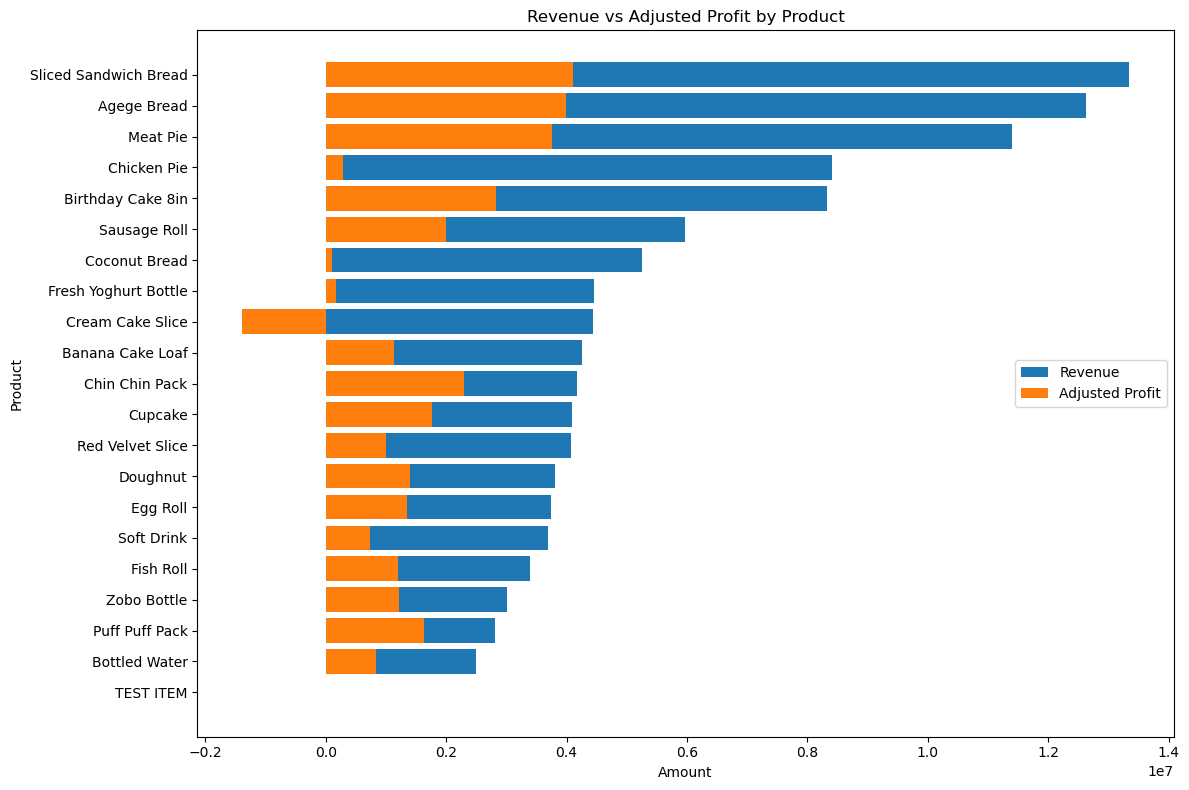

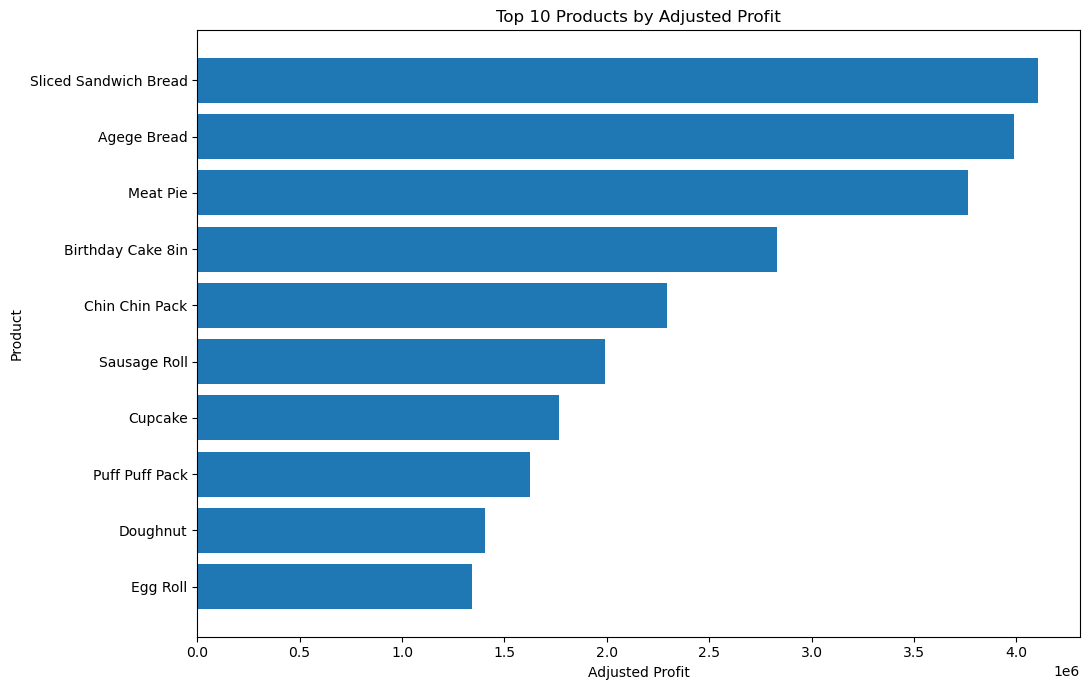

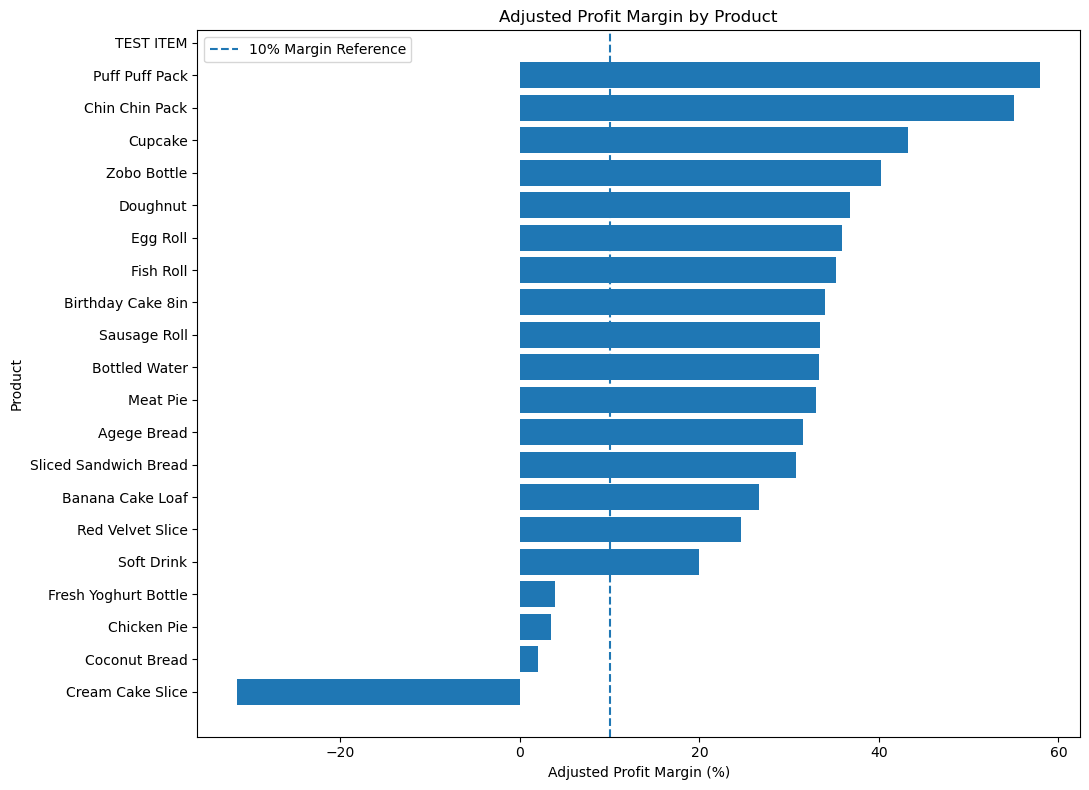

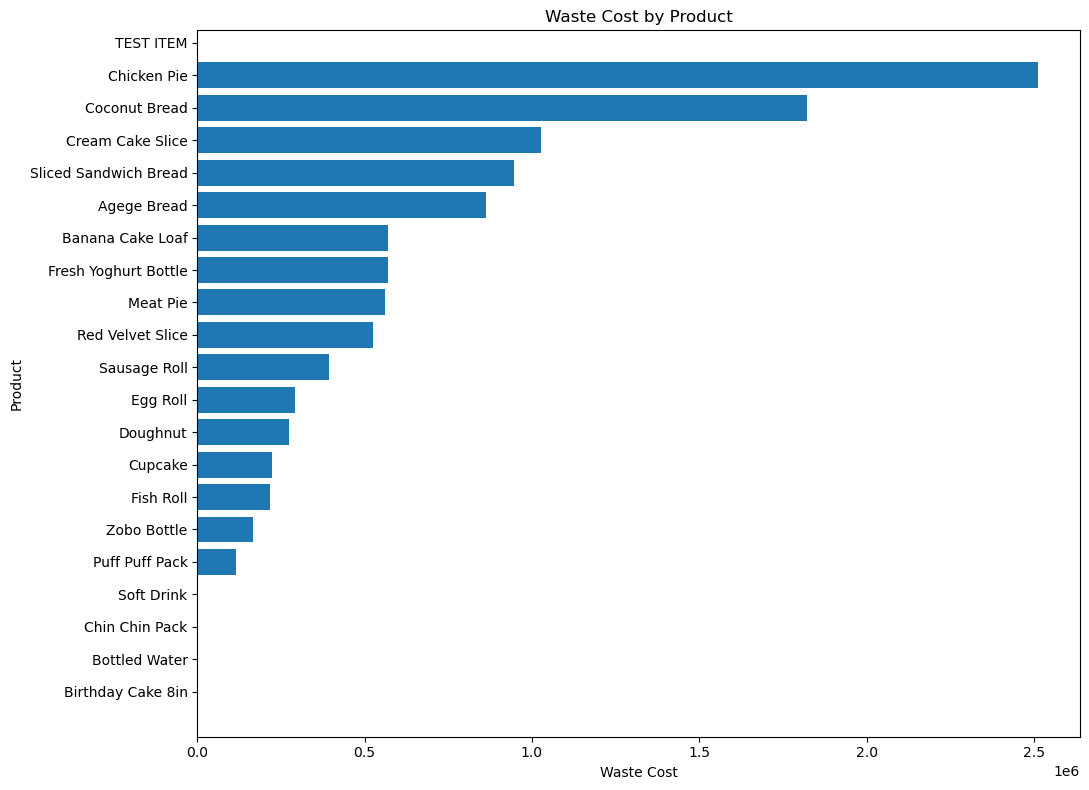

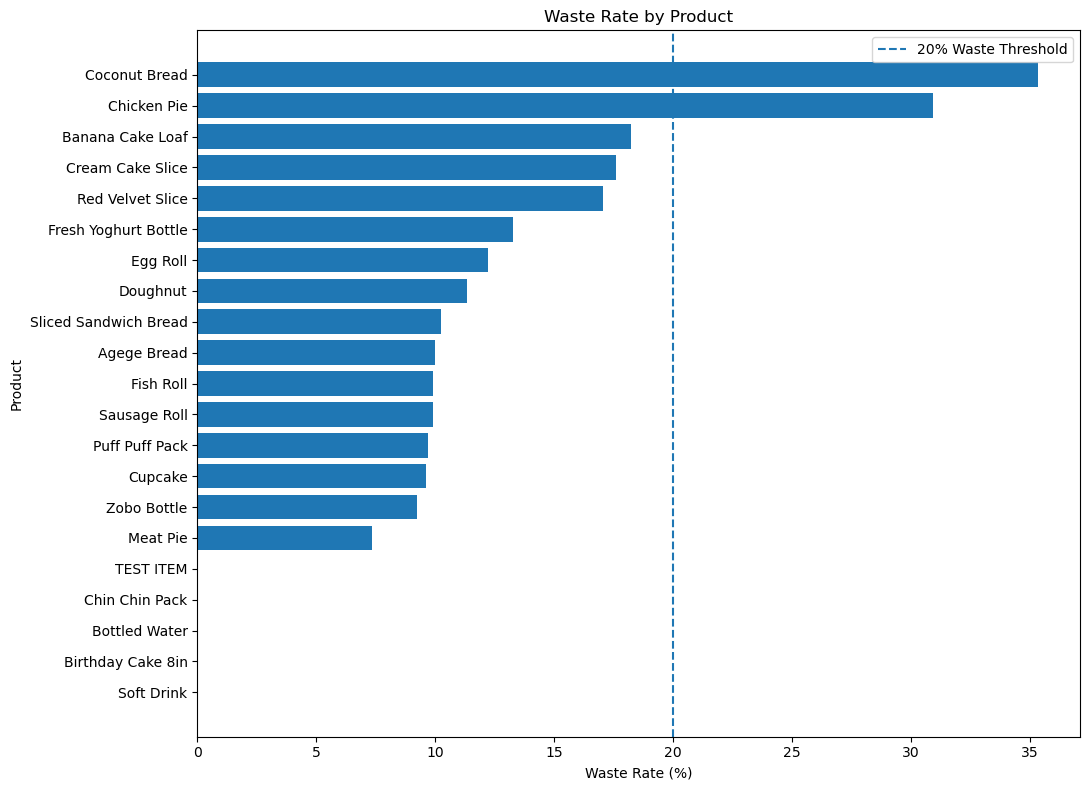

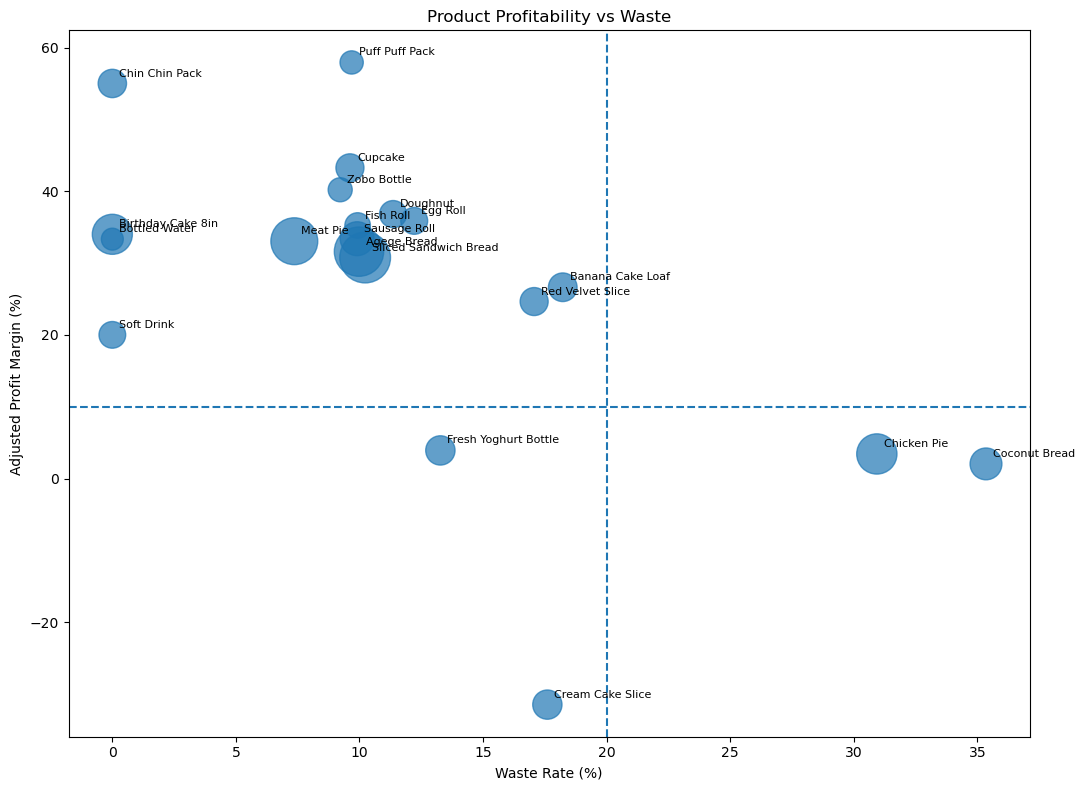

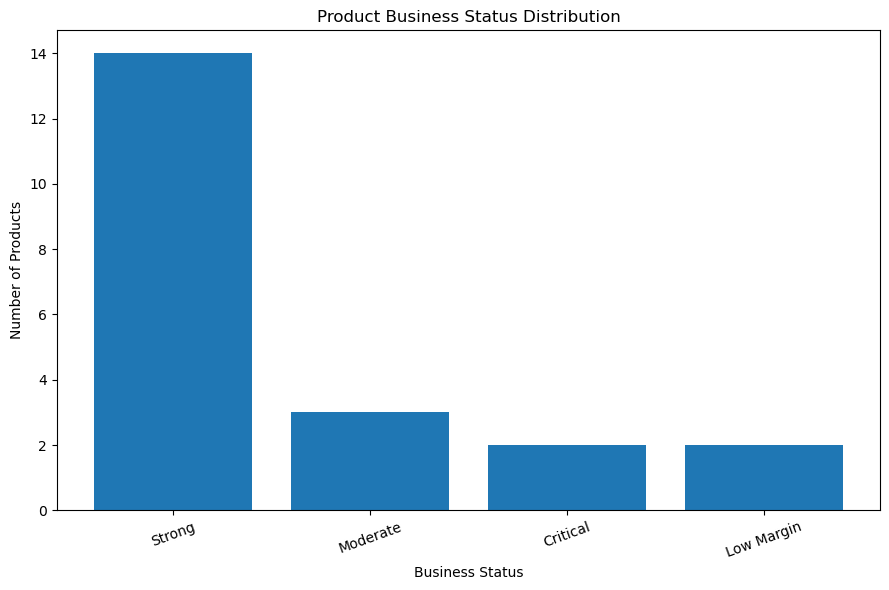


STAGE 6B COMPLETE

Charts saved to:
c:\Users\user\Desktop\Bakery dashboard\data\processed\dashboard\charts

Created charts:
✓ 01_revenue_vs_profit.png
✓ 02_top_profit_products.png
✓ 03_profit_margin.png
✓ 04_waste_cost.png
✓ 05_waste_rate.png
✓ 06_profitability_vs_waste.png
✓ 07_business_status.png


In [7]:
# ============================================================
# STAGE 6B — DASHBOARD VISUALIZATIONS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("STAGE 6B — DASHBOARD VISUALIZATIONS")
print("=" * 70)


# ------------------------------------------------------------
# 1. LOAD DASHBOARD DATA
# ------------------------------------------------------------

dashboard_products = pd.read_csv(
    "../data/processed/dashboard/product_dashboard.csv"
)

kpi_summary = pd.read_csv(
    "../data/processed/dashboard/kpi_summary.csv"
)

print("\n✓ Dashboard data loaded")
print("Products:", dashboard_products.shape)


# ------------------------------------------------------------
# 2. CREATE OUTPUT FOLDER
# ------------------------------------------------------------

import os

chart_folder = "../data/processed/dashboard/charts"

os.makedirs(
    chart_folder,
    exist_ok=True
)


# ============================================================
# CHART 1 — REVENUE VS ADJUSTED PROFIT
# ============================================================

plot_data = (
    dashboard_products
    .sort_values("revenue", ascending=True)
)

plt.figure(figsize=(12, 8))

plt.barh(
    plot_data["product_name"],
    plot_data["revenue"],
    label="Revenue"
)

plt.barh(
    plot_data["product_name"],
    plot_data["adjusted_profit"],
    label="Adjusted Profit"
)

plt.xlabel("Amount")
plt.ylabel("Product")
plt.title("Revenue vs Adjusted Profit by Product")
plt.legend()

plt.tight_layout()

plt.savefig(
    f"{chart_folder}/01_revenue_vs_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CHART 2 — TOP 10 PRODUCTS BY ADJUSTED PROFIT
# ============================================================

top10 = (
    dashboard_products
    .sort_values(
        "adjusted_profit",
        ascending=False
    )
    .head(10)
    .sort_values(
        "adjusted_profit",
        ascending=True
    )
)

plt.figure(figsize=(11, 7))

plt.barh(
    top10["product_name"],
    top10["adjusted_profit"]
)

plt.xlabel("Adjusted Profit")
plt.ylabel("Product")
plt.title("Top 10 Products by Adjusted Profit")

plt.tight_layout()

plt.savefig(
    f"{chart_folder}/02_top_profit_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CHART 3 — ADJUSTED PROFIT MARGIN
# ============================================================

margin_data = (
    dashboard_products
    .sort_values(
        "adjusted_margin_pct",
        ascending=True
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    margin_data["product_name"],
    margin_data["adjusted_margin_pct"]
)

plt.axvline(
    x=10,
    linestyle="--",
    label="10% Margin Reference"
)

plt.xlabel("Adjusted Profit Margin (%)")
plt.ylabel("Product")
plt.title("Adjusted Profit Margin by Product")
plt.legend()

plt.tight_layout()

plt.savefig(
    f"{chart_folder}/03_profit_margin.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CHART 4 — WASTE COST BY PRODUCT
# ============================================================

waste_cost_data = (
    dashboard_products
    .sort_values(
        "waste_cost",
        ascending=True
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    waste_cost_data["product_name"],
    waste_cost_data["waste_cost"]
)

plt.xlabel("Waste Cost")
plt.ylabel("Product")
plt.title("Waste Cost by Product")

plt.tight_layout()

plt.savefig(
    f"{chart_folder}/04_waste_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CHART 5 — WASTE RATE BY PRODUCT
# ============================================================

waste_rate_data = (
    dashboard_products
    .sort_values(
        "waste_pct",
        ascending=True
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    waste_rate_data["product_name"],
    waste_rate_data["waste_pct"]
)

plt.axvline(
    x=20,
    linestyle="--",
    label="20% Waste Threshold"
)

plt.xlabel("Waste Rate (%)")
plt.ylabel("Product")
plt.title("Waste Rate by Product")
plt.legend()

plt.tight_layout()

plt.savefig(
    f"{chart_folder}/05_waste_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CHART 6 — PROFITABILITY VS WASTE MATRIX
# ============================================================

plt.figure(figsize=(11, 8))

plt.scatter(
    dashboard_products["waste_pct"],
    dashboard_products["adjusted_margin_pct"],
    s=dashboard_products["revenue"] / 10000,
    alpha=0.7
)

for _, row in dashboard_products.iterrows():

    plt.annotate(
        row["product_name"],
        (
            row["waste_pct"],
            row["adjusted_margin_pct"]
        ),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axvline(
    x=20,
    linestyle="--"
)

plt.axhline(
    y=10,
    linestyle="--"
)

plt.xlabel("Waste Rate (%)")
plt.ylabel("Adjusted Profit Margin (%)")
plt.title(
    "Product Profitability vs Waste"
)

plt.tight_layout()

plt.savefig(
    f"{chart_folder}/06_profitability_vs_waste.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CHART 7 — BUSINESS STATUS DISTRIBUTION
# ============================================================

status_counts = (
    dashboard_products["business_status"]
    .value_counts()
)

plt.figure(figsize=(9, 6))

plt.bar(
    status_counts.index,
    status_counts.values
)

plt.xlabel("Business Status")
plt.ylabel("Number of Products")
plt.title("Product Business Status Distribution")

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    f"{chart_folder}/07_business_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 70)
print("STAGE 6B COMPLETE")
print("=" * 70)

print("\nCharts saved to:")
print(os.path.abspath(chart_folder))

print("\nCreated charts:")

for file in sorted(os.listdir(chart_folder)):
    print("✓", file)

In [8]:
# ============================================================
# STAGE 6C — BUSINESS INSIGHTS & DASHBOARD FINALIZATION
# ============================================================

import pandas as pd
import numpy as np
import os

print("=" * 70)
print("STAGE 6C — BUSINESS INSIGHTS & DASHBOARD FINALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD STAGE 4 PROFITABILITY DATA
# ------------------------------------------------------------

profitability = pd.read_csv(
    "../data/processed/stage4_profitability.csv"
)

print("\n✓ Profitability data loaded")
print("Shape:", profitability.shape)

# ------------------------------------------------------------
# 2. CHECK DATA STRUCTURE
# ------------------------------------------------------------

required_columns = [
    "product_name",
    "units_sold",
    "revenue",
    "unit_cost",
    "cogs",
    "gross_profit",
    "gross_margin_pct",
    "waste_quantity",
    "waste_cost",
    "adjusted_profit",
    "adjusted_margin_pct"
]

missing_columns = [
    col for col in required_columns
    if col not in profitability.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("✓ Required columns verified")

# ------------------------------------------------------------
# 3. CLEAN NUMERIC VALUES
# ------------------------------------------------------------

numeric_columns = [
    "units_sold",
    "revenue",
    "unit_cost",
    "cogs",
    "gross_profit",
    "gross_margin_pct",
    "waste_quantity",
    "waste_cost",
    "adjusted_profit",
    "adjusted_margin_pct"
]

for col in numeric_columns:
    profitability[col] = pd.to_numeric(
        profitability[col],
        errors="coerce"
    )

# Remove rows without product names
profitability = profitability[
    profitability["product_name"].notna()
].copy()

# ------------------------------------------------------------
# 4. CORRECT WASTE PERCENTAGE
# ------------------------------------------------------------

profitability["waste_pct"] = np.where(
    profitability["revenue"] > 0,
    (profitability["waste_cost"] / profitability["revenue"]) * 100,
    0
)

# ------------------------------------------------------------
# 5. REMOVE TEST / INVALID PRODUCTS
# ------------------------------------------------------------

print("\nProducts before validation:")
print(profitability["product_name"].tolist())

invalid_products = profitability[
    profitability["product_name"]
    .astype(str)
    .str.upper()
    .str.contains("TEST")
]["product_name"].tolist()

if invalid_products:
    print("\n⚠ Test/invalid products detected:")
    print(invalid_products)

    profitability = profitability[
        ~profitability["product_name"]
        .astype(str)
        .str.upper()
        .str.contains("TEST")
    ].copy()

print("\nProducts after validation:")
print(profitability["product_name"].tolist())

# ------------------------------------------------------------
# 6. BUSINESS STATUS CLASSIFICATION
# ------------------------------------------------------------

def classify_product(row):

    margin = row["adjusted_margin_pct"]
    waste = row["waste_pct"]

    if margin < 5 and waste >= 20:
        return "Critical"

    elif margin < 10:
        return "Low Margin"

    elif waste >= 20:
        return "High Waste"

    elif margin >= 25:
        return "Strong"

    else:
        return "Moderate"


profitability["business_status"] = profitability.apply(
    classify_product,
    axis=1
)

# ------------------------------------------------------------
# 7. RANK PRODUCTS
# ------------------------------------------------------------

profitability["profit_rank"] = (
    profitability["adjusted_profit"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

profitability["margin_rank"] = (
    profitability["adjusted_margin_pct"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

profitability["waste_rank"] = (
    profitability["waste_pct"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

# ------------------------------------------------------------
# 8. EXECUTIVE KPIs
# ------------------------------------------------------------

total_revenue = profitability["revenue"].sum()
total_adjusted_profit = profitability["adjusted_profit"].sum()
total_waste_cost = profitability["waste_cost"].sum()

overall_adjusted_margin = (
    total_adjusted_profit / total_revenue * 100
    if total_revenue > 0 else 0
)

total_units_sold = profitability["units_sold"].sum()

average_product_margin = (
    profitability["adjusted_margin_pct"].mean()
)

high_waste_count = (
    profitability["waste_pct"] >= 20
).sum()

low_margin_count = (
    profitability["adjusted_margin_pct"] < 10
).sum()

critical_count = (
    profitability["business_status"] == "Critical"
).sum()

# ------------------------------------------------------------
# 9. CREATE KPI TABLE
# ------------------------------------------------------------

kpi_summary = pd.DataFrame({
    "metric": [
        "Total Revenue",
        "Total Adjusted Profit",
        "Total Waste Cost",
        "Overall Adjusted Margin",
        "Total Units Sold",
        "Average Product Margin",
        "High Waste Products",
        "Low Margin Products",
        "Critical Products",
        "Total Products"
    ],

    "value": [
        total_revenue,
        total_adjusted_profit,
        total_waste_cost,
        overall_adjusted_margin,
        total_units_sold,
        average_product_margin,
        high_waste_count,
        low_margin_count,
        critical_count,
        len(profitability)
    ]
})

# ------------------------------------------------------------
# 10. TOP PROFIT PRODUCTS
# ------------------------------------------------------------

top_profit_products = (
    profitability
    .sort_values("adjusted_profit", ascending=False)
    .head(10)
)

# ------------------------------------------------------------
# 11. PRODUCTS REQUIRING ATTENTION
# ------------------------------------------------------------

products_requiring_attention = profitability[
    profitability["business_status"].isin(
        ["Critical", "Low Margin", "High Waste"]
    )
].sort_values(
    ["business_status", "adjusted_margin_pct"],
    ascending=[True, True]
)

# ------------------------------------------------------------
# 12. HIGH WASTE PRODUCTS
# ------------------------------------------------------------

high_waste_products = (
    profitability[
        profitability["waste_pct"] >= 20
    ]
    .sort_values("waste_pct", ascending=False)
)

# ------------------------------------------------------------
# 13. BUSINESS STATUS SUMMARY
# ------------------------------------------------------------

status_summary = (
    profitability["business_status"]
    .value_counts()
    .rename_axis("business_status")
    .reset_index(name="product_count")
)

# ------------------------------------------------------------
# 14. SAVE FINAL DASHBOARD DATA
# ------------------------------------------------------------

dashboard_folder = "../data/processed/dashboard"

os.makedirs(dashboard_folder, exist_ok=True)

profitability.to_csv(
    f"{dashboard_folder}/product_dashboard.csv",
    index=False
)

kpi_summary.to_csv(
    f"{dashboard_folder}/kpi_summary.csv",
    index=False
)

top_profit_products.to_csv(
    f"{dashboard_folder}/top_profit_products.csv",
    index=False
)

products_requiring_attention.to_csv(
    f"{dashboard_folder}/products_requiring_attention.csv",
    index=False
)

high_waste_products.to_csv(
    f"{dashboard_folder}/high_waste_products.csv",
    index=False
)

status_summary.to_csv(
    f"{dashboard_folder}/status_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 15. DISPLAY EXECUTIVE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXECUTIVE BUSINESS SUMMARY")
print("=" * 70)

print(f"\nTotal Revenue:          ₦{total_revenue:,.0f}")
print(f"Adjusted Profit:        ₦{total_adjusted_profit:,.0f}")
print(f"Waste Cost:             ₦{total_waste_cost:,.0f}")
print(f"Adjusted Margin:        {overall_adjusted_margin:.2f}%")
print(f"Units Sold:             {total_units_sold:,.0f}")

print(f"\nHigh Waste Products:    {high_waste_count}")
print(f"Low Margin Products:    {low_margin_count}")
print(f"Critical Products:      {critical_count}")

print("\n" + "=" * 70)
print("TOP 5 PRODUCTS BY ADJUSTED PROFIT")
print("=" * 70)

print(
    profitability[
        [
            "product_name",
            "adjusted_profit",
            "adjusted_margin_pct",
            "waste_pct"
        ]
    ]
    .sort_values("adjusted_profit", ascending=False)
    .head(5)
    .to_string(index=False)
)

print("\n" + "=" * 70)
print("TOP 5 PRODUCTS BY WASTE RATE")
print("=" * 70)

print(
    profitability[
        [
            "product_name",
            "waste_cost",
            "waste_pct",
            "adjusted_margin_pct"
        ]
    ]
    .sort_values("waste_pct", ascending=False)
    .head(5)
    .to_string(index=False)
)

print("\n" + "=" * 70)
print("STAGE 6C COMPLETE")
print("=" * 70)

print("\n✓ Dashboard dataset finalized")
print("✓ Waste percentage standardized")
print("✓ Test products removed")
print("✓ Business statuses generated")
print("✓ Executive KPIs generated")
print("✓ Dashboard files saved")

STAGE 6C — BUSINESS INSIGHTS & DASHBOARD FINALIZATION

✓ Profitability data loaded
Shape: (21, 11)
✓ Required columns verified

Products before validation:
['Agege Bread', 'Banana Cake Loaf', 'Birthday Cake 8in', 'Bottled Water', 'Chicken Pie', 'Chin Chin Pack', 'Coconut Bread', 'Cream Cake Slice', 'Cupcake', 'Doughnut', 'Egg Roll', 'Fish Roll', 'Fresh Yoghurt Bottle', 'Meat Pie', 'Puff Puff Pack', 'Red Velvet Slice', 'Sausage Roll', 'Sliced Sandwich Bread', 'Soft Drink', 'TEST ITEM', 'Zobo Bottle']

⚠ Test/invalid products detected:
['TEST ITEM']

Products after validation:
['Agege Bread', 'Banana Cake Loaf', 'Birthday Cake 8in', 'Bottled Water', 'Chicken Pie', 'Chin Chin Pack', 'Coconut Bread', 'Cream Cake Slice', 'Cupcake', 'Doughnut', 'Egg Roll', 'Fish Roll', 'Fresh Yoghurt Bottle', 'Meat Pie', 'Puff Puff Pack', 'Red Velvet Slice', 'Sausage Roll', 'Sliced Sandwich Bread', 'Soft Drink', 'Zobo Bottle']

EXECUTIVE BUSINESS SUMMARY

Total Revenue:          ₦113,745,100
Adjusted Profit: